# Листок № 1. СЛАУ, матрицы, квадратичные формы

*Составитель: д.ф.-м.н., проф. Рябов П.Е.*

## Задача 1.1 (с использованием Jupyter Notebook)

Найти общее решение системы линейных уравнений

$$\begin{cases} x_1 + 5x_2 - 2x_3 = -7,\\ -3x_1 + x_2 + 9x_3 - 5x_4 = 9,\\ 4x_1 - 8x_2 - x_3 + 7x_4 = 0.\end{cases}$$

In [9]:
import numpy as np
import scipy.linalg as la
from sympy import * # type: ignore

init_printing()

A = np.array([[1,5,-2,0],[-3,1,9,-5],[4,-8,-1,7]])
b = np.array([-7,9,0]).reshape(3,1)

A_b = np.hstack([A,b])

Matrix(A_b).rref()

⎛⎡1  0  0  8/7   -11/7⎤           ⎞
⎜⎢                    ⎥           ⎟
⎜⎢0  1  0  -2/7  -6/7 ⎥, (0, 1, 2)⎟
⎜⎢                    ⎥           ⎟
⎝⎣0  0  1  -1/7   4/7 ⎦           ⎠

## Задача 1.2 (с использованием Jupyter Notebook)

Найдите: а) rref (Reduced Row Echelon Form) расширенной матрицы и б) общее решение системы линейных уравнений

$$\begin{cases} 5x_1 - x_2 + 5x_3 + 9x_4 - 2x_5 = -3,\\ 3x_1 + 6x_3 + 9x_4 - x_5 = 4,\\ 2x_1 + 4x_3 + 6x_4 - x_5 = 0.\end{cases}$$

In [10]:
A = np.array([[5,-1,5,9,-2],[3,0,6,9,-1],[2,0,4,6,-1]])
b = np.array([-3,4,0]).reshape(3,1)
A_b = np.hstack([A,b])

Matrix(A_b).rref()

⎛⎡1  0  2  3  0  4⎤           ⎞
⎜⎢                ⎥           ⎟
⎜⎢0  1  5  6  0  7⎥, (0, 1, 4)⎟
⎜⎢                ⎥           ⎟
⎝⎣0  0  0  0  1  8⎦           ⎠

In [11]:
x1, x2, x3, x4, x5 = symbols('x1:6')
linsolve((Matrix(A), Matrix(b)), [x1, x2, x3, x4, x5])

## Задача 1.3

Пусть $(x, y, z, u)$ – решение системы уравнений:

$$\begin{cases} 32x + 97y + 90z + 48u = 47\\ 35x + 84y + 91z + 54u = 40\\ 17x + 18y + 21z + 13u = 37\end{cases}$$

Объясните, почему $y$ можно представить как функцию от $x$ вида $y = a + bx$, где $a, b$ – константы, зависящие только от коэффициентов исходной системы уравнений. Найдите: 1) константу $a$; 2) константу $b$.

**Ответ:** 1) $a = 14027$. 2) $b = -4262$.

In [12]:
# ранг системы 3, а неизвестных 4, поэтому есть одна свободная переменная
# значит x, y, z, u линейно зависят от неё, а следовательно и друг от друга
x,y,z,u = symbols('x y z u')
eqs = [Eq(32*x+97*y+90*z+48*u,47),
       Eq(35*x+84*y+91*z+54*u,40),
       Eq(17*x+18*y+21*z+13*u,37)]
sol = solve(eqs,[x,y,z,u])
sol

In [13]:
# выражаем u через x и подставляем в y, чтобы получить y как функцию от x
u_expr = solve(Eq(x, sol[x]), u)[0]
y_expr = expand(sol[y].subs(u, u_expr))
y_expr

In [14]:
a = y_expr.subs(x,0)
b = y_expr.coeff(x)
a, b

## Задача 1.4

Выполнить действия

$$\begin{pmatrix}3&0&2\\0&1&3\\2&2&0\\0&1&0\end{pmatrix}\cdot\begin{pmatrix}1&2&-1&2\\-2&-1&1&2\\2&1&1&2\end{pmatrix}+\begin{pmatrix}0&-4&6&1\\2&2&-5&-2\\2&-2&6&4\\1&3&0&1\end{pmatrix}.$$

In [15]:
M1 = Matrix([[3,0,2],[0,1,3],[2,2,0],[0,1,0]])
M2 = Matrix([[1,2,-1,2],[-2,-1,1,2],[2,1,1,2]])
M3 = Matrix([[0,-4,6,1],[2,2,-5,-2],[2,-2,6,4],[1,3,0,1]])

M1*M2 + M3

⎡7   4  5   11⎤
⎢             ⎥
⎢6   4  -1  6 ⎥
⎢             ⎥
⎢0   0  6   12⎥
⎢             ⎥
⎣-1  2  1   3 ⎦

## Задача 1.5

Найдите определители порядка $n$, элементы которого заданы условием:

а) $a_{ij} = \min(i,j)$; б) $a_{ij} = \max(i,j)$; в)$^*$ $a_{ij} = |i-j|$.

In [16]:
# считаем определители для маленьких n, чтобы увидеть закономерность
for n in range(1,7):
    A_min = Matrix(n,n, lambda i,j: min(i+1,j+1))
    A_max = Matrix(n,n, lambda i,j: max(i+1,j+1))
    A_abs = Matrix(n,n, lambda i,j: abs(i-j))
    print(n, A_min.det(), A_max.det(), A_abs.det())

1 1 1 0
2 1 -2 -1
3 1 3 4
4 1 -4 -12
5 1 5 32
6 1 -6 -80


а) det = 1

б) det = (-1)^(n-1) * n

в) det = (-1)^(n-1) * (n-1) * 2^(n-2)

## Задача 1.7

Матрица $A=(a_{i,j})$ имеет размер $n\times n$, где $n=80000$. Известно, что её диагональные элементы образуют арифметическую прогрессию с начальным элементом $a_{1,1}=0.99$ и конечным элементом $a_{n,n}=1.01$. Также известно, что все элементы матрицы $A$, расположенные вне главной диагонали, равны нулю, за исключением двух элементов: $a_{1,2}=0.57$ и $a_{2,1}=0.03$. Найдите: 1) определитель матрицы $A$; 2) след матрицы, обратной к $A$.

**Ответ:** 1) $0.259$; 2) $80002.703$.

In [18]:
# матрица блочно-диагональная: блок 2x2 в углу и диагональ дальше
n = 80000
diag = np.linspace(0.99, 1.01, n)
a12, a21 = 0.57, 0.03

det_block = diag[0]*diag[1] - a12*a21
detA = det_block * np.prod(diag[2:])
detA

In [19]:
# след обратной матрицы = след обратного блока 2x2 + сумма 1/(остальные диагональные элементы)
trace_invA = (diag[0]+diag[1])/det_block + np.sum(1/diag[2:])
trace_invA

## Задача 1.8

Матрица $A=(a_{i,j})$ имеет размер $n\times n$, где $n=43000$. Известно, что: 1) диагональные элементы образуют геометрическую прогрессию с начальным элементом $a_{1,1}=1$ и конечным элементом $a_{n,n}=1.07$; 2) элементы первой строки образуют арифметическую прогрессию с конечным элементом $a_{1,n}=1.10$; 3) все элементы матрицы $A$, расположенные вне главной диагонали и вне первой строки, равны нулю. Найдите обратную матрицу $B=A^{-1}$ и укажите: 1) наименьший элемент матрицы $B$; 2) сумму элементов матрицы $B$.

**Ответ:** 1) $-1.028$; 2) $-2054.4$.

In [20]:
# матрица верхнетреугольная, вне диагонали ненулевая только первая строка
n = 43000
r = 1.07**(1/(n-1))
diag = r**np.arange(n)                  # a11=1 ... ann=1.07, геометрическая прогрессия
first_row = np.linspace(1, 1.10, n)     # a11=1 ... a1n=1.10, арифметическая прогрессия

# для такой матрицы обратная считается по простой формуле
B00 = 1/diag[0]
B0j = -first_row[1:]/diag[1:]
Bii = 1/diag[1:]

min_elem = min(B00, B0j.min(), Bii.min())
sum_elem = B00 + B0j.sum() + Bii.sum()
min_elem, sum_elem

## Задача 1.9

Даны матрицы:
$$I=\begin{pmatrix}1&0\\0&1\end{pmatrix},\ A=\begin{pmatrix}7\gamma&14\gamma\\9\gamma&1\gamma\end{pmatrix},\ \text{где } \gamma=0.057.$$

Пусть $S_{m,n}=\sum_{i=m}^{n}A^i$, $B_m=(I-A)^{-1}A^m$.
1) Найдите наибольший элемент матрицы $S=S_{4,70}$.
2) Найдите наибольший элемент матрицы $B=B_4$.
3) Найдите наименьшее $k$, такое, что при любом $n>k$ наибольший элемент матрицы $S_{k,n}$ меньше $0.0002$.

**Ответ:** 1) $3.609679$; 2) $3.611175$; 3) $89$.

In [21]:
gamma = 0.057
A = np.array([[7*gamma,14*gamma],[9*gamma,1*gamma]])
I2 = np.eye(2)

w, v = np.linalg.eig(A)
vinv = np.linalg.inv(v)

def Apow(k):
    return (v * w**k) @ vinv

S = sum(Apow(i) for i in range(4,71)).real
S.max()

In [22]:
B4 = np.linalg.inv(I2-A) @ Apow(4).real
B4.max()

In [23]:
# ищем наименьшее k, начиная с которого хвост суммы всегда меньше 0.0002
def max_S(k, n):
    return sum(Apow(i) for i in range(k,n+1)).real.max()

k = 1
while max_S(k, k+300) >= 0.0002:
    k += 1
k

## Задача 1.10

Дана матрица:
$$M=\begin{pmatrix}7&5&5&x\\2&2&6&9\\3&x&8&0\\3&1&1&0\end{pmatrix}.$$

Запишите определитель матрицы $M$ в виде многочлена $ax^2+bx+c$. В ответе укажите: 1) значение коэффициента $a$; 2) значение коэффициента $b$.

In [24]:
x = symbols('x')
M = Matrix([[7,5,5,x],[2,2,6,9],[3,x,8,0],[3,1,1,0]])
d = expand(M.det())
d

In [25]:
a,b,c = Poly(d,x).all_coeffs()
a,b,c

## Задача 1.11 (с использованием Jupyter Notebook)

Используя графические возможности, изобразите матрицу размера $n\times n$ для $n=100$, каждая строка которой содержит элементы биномиальных коэффициентов по модулю 2 (закрашенный «синий» квадратик соответствует 1, «жёлтый» закрашенный — 0).

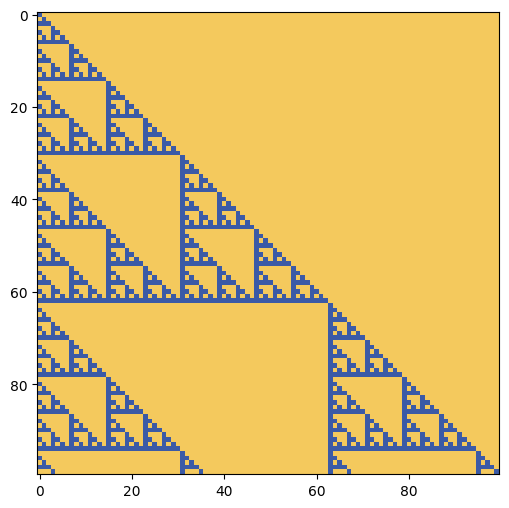

In [26]:
import matplotlib
import matplotlib.pyplot as plt
from math import comb

n = 100
C = np.zeros((n,n), dtype=int)
for i in range(1,n+1):
    for j in range(1,i+1):
        C[i-1,j-1] = comb(i,j) % 2

cmap = matplotlib.colors.ListedColormap(['#f4c95d','#3b5aa6'])  # type: ignore # 0 - желтый, 1 - синий
plt.figure(figsize=(6,6))
plt.imshow(C, cmap=cmap)
plt.show()

## Задача 1.12

Матрица Адамара $H$ — это квадратная матрица размера $n\times n$, составленная из чисел $1$ и $-1$, столбцы которой удовлетворяют соотношению $H_n\cdot H_n^T = n\cdot I_n$, где $I_n$ — единичная матрица порядка $n$, $H_0\equiv 1$.

а) Выпишите $H_1, H_2, H_4$ в явном виде;
б) Покажите, что $H_4=H_2\otimes H_2$;
в)$^*$ Покажите, что $H_{2^k}=H_2\otimes H_{2^{k-1}}$, где $2\le k\in\mathbb{N}$, а $\otimes$ означает произведение Кронекера;
г) Используя графические возможности, изобразите матрицу Адамара для $n=2^6$ (положительный элемент — «оранжевый», отрицательный — «синий»).

In [27]:
H1 = Matrix([1])
H2 = Matrix([[1,1],[1,-1]])
H4 = Matrix([[1,1,1,1],[1,-1,1,-1],[1,1,-1,-1],[1,-1,-1,1]])
H1, H2, H4

⎛              ⎡1  1   1   1 ⎤⎞
⎜              ⎢             ⎥⎟
⎜     ⎡1  1 ⎤  ⎢1  -1  1   -1⎥⎟
⎜[1], ⎢     ⎥, ⎢             ⎥⎟
⎜     ⎣1  -1⎦  ⎢1  1   -1  -1⎥⎟
⎜              ⎢             ⎥⎟
⎝              ⎣1  -1  -1  1 ⎦⎠

In [28]:
from sympy.matrices.expressions.kronecker import kronecker_product

# б) проверяем что H4 = H2 (x) H2
kronecker_product(H2,H2).as_explicit() == H4 # type: ignore

True

в) по индукции: если H_{2^(k-1)} матрица Адамара, то (H2⊗H)(H2⊗H)^T = (H2 H2^T)⊗(H H^T) = (2I_2)⊗(2^(k-1) I) = 2^k I, значит H2⊗H_{2^(k-1)} тоже матрица Адамара порядка 2^k

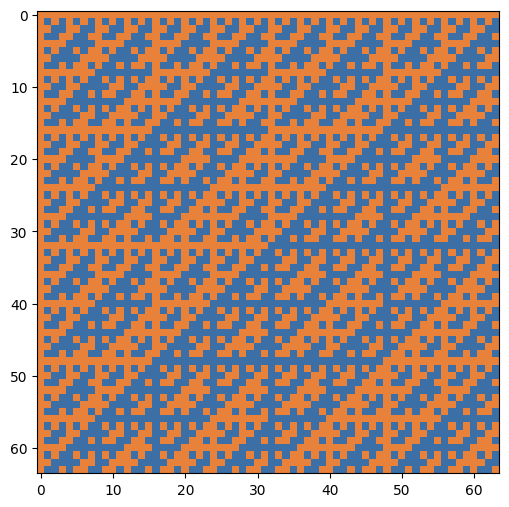

In [29]:
# г) H_64 = H2 (x) H2 (x) ... (x) H2, 6 раз
H = np.array([[1,1],[1,-1]])
Hn = H.copy()
for _ in range(5):
    Hn = np.kron(H, Hn)

cmap = matplotlib.colors.ListedColormap(['#3b6fa6','#e8813a'])  # type: ignore  # -1 - синий, 1 - оранжевый
plt.figure(figsize=(6,6))
plt.imshow(Hn, cmap=cmap)
plt.show()

## Задача 1.13

Дана матрица:
$$A=\begin{pmatrix}14&10&21\\12&15&26\\18&11&27\end{pmatrix}.$$

Пусть $Z$ — собственное значение матрицы $A$ с наибольшей мнимой частью. Найдите $Z$ и соответствующий этому собственному значению собственный вектор $X$, первая координата которого равна 1, $X=(1,U,V)$. В ответе укажите: 1) мнимую часть $Z$; 2) действительную часть $U$.

In [30]:
A = np.array([[14,10,21],[12,15,26],[18,11,27]], dtype=float)
w, v = np.linalg.eig(A)
w

array([52.06231934+0.j        ,  1.96884033+0.34478935j,
        1.96884033-0.34478935j])

In [31]:
# берём собственное значение с наибольшей мнимой частью и нормируем вектор так, чтобы X[0]=1
idx = np.argmax(w.imag)
Z = w[idx]
X = v[:,idx] / v[0,idx]
Z, X

(np.complex128(1.968840330801648+0.34478934842718173j),
 array([ 1.        -1.73026019e-18j,  3.74781973+1.33084677e+00j,
        -2.35758843-6.17318019e-01j]))

## Задача 1.14

Найдите минимальный многочлен матрицы
$$A=\begin{pmatrix}
-3&7&-6&-1&8&-3&-2\\
1&-5&8&-3&-5&4&-5\\
1&3&-4&6&-2&0&8\\
-1&11&-12&9&3&-3&9\\
-3&11&-12&5&8&-4&6\\
-3&2&1&-4&4&1&-7\\
1&-5&6&-2&-4&3&-2
\end{pmatrix}$$

In [32]:
A = Matrix([
[-3, 7, -6, -1, 8, -3, -2],
[1, -5, 8, -3, -5, 4, -5],
[1, 3, -4, 6, -2, 0, 8],
[-1, 11, -12, 9, 3, -3, 9],
[-3, 11, -12, 5, 8, -4, 6],
[-3, 2, 1, -4, 4, 1, -7],
[1, -5, 6, -2, -4, 3, -2],
])
x = symbols('x')
factor(A.charpoly(x).as_expr())

In [33]:
# минимальный многочлен делит характеристический и имеет те же корни
# подбираем наименьшие степени, при которых он аннулирует матрицу
I = eye(7)
zeros(7) == A**3*(A-I)**2, zeros(7) == A**2*(A-I)**2, zeros(7) == A**3*(A-I)

(True, False, False)

значит минимальный многочлен: μ(x) = x³(x-1)²

## Задача 1.15

Найдите собственный ортонормированный базис и матрицу в этом базисе самосопряжённого оператора $\varphi$, заданного в некотором ортонормированном базисе $(e)$ матрицей
$$A_{\varphi}^{(e)}=\begin{pmatrix}17&-8&4\\-8&17&-4\\4&-4&11\end{pmatrix}.$$

In [34]:
A = Matrix([[17,-8,4],[-8,17,-4],[4,-4,11]])
A.eigenvects()

⎡⎛      ⎡⎡1⎤  ⎡-1/2⎤⎤⎞  ⎛       ⎡⎡2 ⎤⎤⎞⎤
⎢⎜      ⎢⎢ ⎥  ⎢    ⎥⎥⎟  ⎜       ⎢⎢  ⎥⎥⎟⎥
⎢⎜9, 2, ⎢⎢1⎥, ⎢ 0  ⎥⎥⎟, ⎜27, 1, ⎢⎢-2⎥⎥⎟⎥
⎢⎜      ⎢⎢ ⎥  ⎢    ⎥⎥⎟  ⎜       ⎢⎢  ⎥⎥⎟⎥
⎣⎝      ⎣⎣0⎦  ⎣ 1  ⎦⎦⎠  ⎝       ⎣⎣1 ⎦⎦⎠⎦

In [35]:
# ортонормируем собственные векторы (векторы для λ=9 ортогонализуем грам-шмидтом)
v1 = Matrix([1,1,0])
v2 = Matrix([Rational(-1,2),0,1])
v3 = Matrix([2,-2,1])

e1, e2 = GramSchmidt([v1,v2], orthonormal=True)
e3 = v3/v3.norm()

Q = Matrix.hstack(e1,e2,e3)
Q

⎡√2  -√2       ⎤
⎢──  ────  2/3 ⎥
⎢2    6        ⎥
⎢              ⎥
⎢√2   √2       ⎥
⎢──   ──   -2/3⎥
⎢2    6        ⎥
⎢              ⎥
⎢    2⋅√2      ⎥
⎢0   ────  1/3 ⎥
⎣     3        ⎦

In [36]:
# матрица оператора в новом базисе - диагональная, из собственных значений
simplify(Q.T*A*Q)

⎡9  0  0 ⎤
⎢        ⎥
⎢0  9  0 ⎥
⎢        ⎥
⎣0  0  27⎦

## Задача 1.16

Найдите ортогональное преобразование, приводящее квадратичную функцию к главным осям
$$f(x_1,x_2,x_3,x_4)=3x_1^2+8x_1x_2-3x_2^2+4x_3^2-4x_3x_4+x_4^2.$$

In [37]:
A = Matrix([
 [3,4,0,0],
 [4,-3,0,0],
 [0,0,4,-2],
 [0,0,-2,1]
])
A.eigenvects()

⎡⎛       ⎡⎡-1/2⎤⎤⎞  ⎛      ⎡⎡ 0 ⎤⎤⎞  ⎛      ⎡⎡2⎤  ⎡0 ⎤⎤⎞⎤
⎢⎜       ⎢⎢    ⎥⎥⎟  ⎜      ⎢⎢   ⎥⎥⎟  ⎜      ⎢⎢ ⎥  ⎢  ⎥⎥⎟⎥
⎢⎜       ⎢⎢ 1  ⎥⎥⎟  ⎜      ⎢⎢ 0 ⎥⎥⎟  ⎜      ⎢⎢1⎥  ⎢0 ⎥⎥⎟⎥
⎢⎜-5, 1, ⎢⎢    ⎥⎥⎟, ⎜0, 1, ⎢⎢   ⎥⎥⎟, ⎜5, 2, ⎢⎢ ⎥, ⎢  ⎥⎥⎟⎥
⎢⎜       ⎢⎢ 0  ⎥⎥⎟  ⎜      ⎢⎢1/2⎥⎥⎟  ⎜      ⎢⎢0⎥  ⎢-2⎥⎥⎟⎥
⎢⎜       ⎢⎢    ⎥⎥⎟  ⎜      ⎢⎢   ⎥⎥⎟  ⎜      ⎢⎢ ⎥  ⎢  ⎥⎥⎟⎥
⎣⎝       ⎣⎣ 0  ⎦⎦⎠  ⎝      ⎣⎣ 1 ⎦⎦⎠  ⎝      ⎣⎣0⎦  ⎣1 ⎦⎦⎠⎦

In [38]:
# нормируем собственные векторы и составляем из них ортогональную матрицу перехода
v1 = Matrix([-1,2,0,0])
v2 = Matrix([2,1,0,0])
v3 = Matrix([0,0,-2,1])
v4 = Matrix([0,0,1,2])

Q = Matrix.hstack(*[v/v.norm() for v in [v1,v2,v3,v4]])
Q

⎡-√5   2⋅√5              ⎤
⎢────  ────    0      0  ⎥
⎢ 5     5                ⎥
⎢                        ⎥
⎢2⋅√5   √5               ⎥
⎢────   ──     0      0  ⎥
⎢ 5     5                ⎥
⎢                        ⎥
⎢            -2⋅√5    √5 ⎥
⎢ 0     0    ──────   ── ⎥
⎢              5      5  ⎥
⎢                        ⎥
⎢              √5    2⋅√5⎥
⎢ 0     0      ──    ────⎥
⎣              5      5  ⎦

In [39]:
# в новых координатах f = -5y1^2 + 5y2^2 + 5y3^2 + 0*y4^2
simplify(Q.T*A*Q)

⎡-5  0  0  0⎤
⎢           ⎥
⎢0   5  0  0⎥
⎢           ⎥
⎢0   0  5  0⎥
⎢           ⎥
⎣0   0  0  0⎦

## Задача 1.17

Определите тип кривой второго порядка, её каноническое уравнение и найдите каноническую систему координат, если кривая задана уравнением:

a) $5x^2+4xy+8y^2-32x-56y+80=0$;

b) $5x^2+12xy-22x-12y-19=0$.

In [40]:
# а) 5x^2 + 4xy + 8y^2 - 32x - 56y + 80 = 0
A = Matrix([[5,2],[2,8]])
lin = Matrix([-16,-28])
F = 80

lam = A.eigenvals()             # собственные значения - коэффициенты канонического уравнения
x0 = -A.inv()*lin                # центр кривой (после сдвига линейные члены пропадают)
c = (lin.T*A.inv()*lin)[0] - F   # правая часть канонического уравнения

print("собственные значения:", lam)
print("центр:", tuple(x0))
print("каноническое уравнение: 4x''^2 + 9y''^2 =", c, "-> эллипс")

собственные значения: {9: 1, 4: 1}
центр: (2, 3)
каноническое уравнение: 4x''^2 + 9y''^2 = 36 -> эллипс


In [41]:
# b) 5x^2 + 12xy - 22x - 12y - 19 = 0
A = Matrix([[5,6],[6,0]])
lin = Matrix([-11,-6])
F = -19

lam = A.eigenvals()
x0 = -A.inv()*lin
c = (lin.T*A.inv()*lin)[0] - F

print("собственные значения:", lam)
print("центр:", tuple(x0))
print("каноническое уравнение: -4x''^2 + 9y''^2 =", c, "-> гипербола")

собственные значения: {9: 1, -4: 1}
центр: (1, 1)
каноническое уравнение: -4x''^2 + 9y''^2 = 36 -> гипербола


## Задача 1.18

При каких значениях параметра $\lambda$ квадратичная форма $Q(x)$ является положительно определённой, если
$$Q(x_1,x_2,x_3)=x_1^2+4x_2^2+x_3^2+2\lambda x_1x_2+10x_1x_3+6x_2x_3.$$

In [42]:
lam = symbols('lambda', real=True)
M = Matrix([[1,lam,5],[lam,4,3],[5,3,1]])
d1,d2,d3 = M[0,0], M[:2,:2].det(), M.det()  # type: ignore
d1, d2, d3

In [43]:
# критерий сильвестра: нужны все три угловых минора положительные
solve([d1>0, d2>0, d3>0], lam)  # type: ignore

условия не пересекаются ни при каких λ, значит форма Q никогда не является положительно определённой

## Задача 1.19

При каких значениях параметра $\lambda$ квадратичная форма $Q(x)$ является отрицательно определённой, если
$$Q(x_1,x_2,x_3)=\lambda x_1^2-2x_2^2-3x_3^2+2x_1x_2-2x_1x_3+2x_2x_3.$$

In [44]:
M = Matrix([[lam,1,-1],[1,-2,1],[-1,1,-3]])
d1,d2,d3 = M[0,0], M[:2,:2].det(), M.det()  # type: ignore
d1, d2, d3

In [45]:
# критерий сильвестра для отрицательной определенности: знаки миноров чередуются, начиная с минуса
solve([d1<0, d2>0, d3<0], lam)  # type: ignore

## Задача 1.20

Эквивалентны ли над полем вещественных чисел квадратичные формы $Q_1$ и $Q_2$, где
$$Q_1=2x_1^2+9x_2^2+3x_3^2+8x_1x_2-4x_1x_3-10x_2x_3;$$
$$Q_2=2x_1^2+3x_2^2+6x_3^2-4x_1x_2-4x_1x_3+8x_2x_3?$$

In [46]:
Q1 = Matrix([[2,4,-2],[4,9,-5],[-2,-5,3]])
Q2 = Matrix([[2,-2,-2],[-2,3,4],[-2,4,6]])

Q1.eigenvals(), Q2.eigenvals()

у обеих форм собственные значения: два положительных и один нулевой (sqrt(43)<7 и sqrt(73)<11), значит ранг и сигнатура совпадают (2,0,1) → по закону инерции Сильвестра формы эквивалентны